# Lab 02-02 · First-Order Linear ODEs

Companion to chapter [02-02](../../chapters/02-02-first-order-linear-odes.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
rng = np.random.default_rng(1)

## Part 1 — Direction fields and finite-time blow-up

We draw the slope field of three equations and overlay solutions computed with SciPy's adaptive integrator.

**🔮 Predict:** where does the solution of $y' = y^2$, $y(0) = 1$, go, and when?

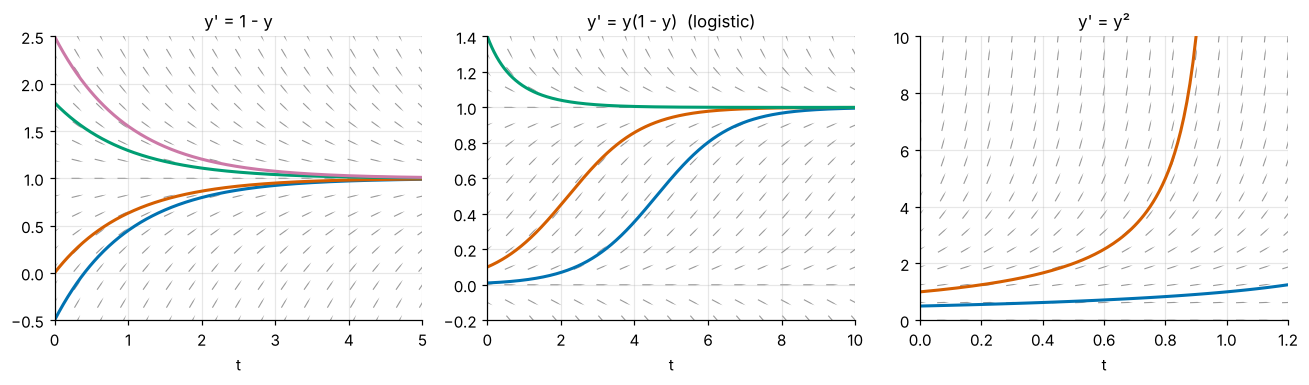

y' = y², y(0) = 1 reaches 10^6 at t = 0.999999 (exact blow-up at t = 1)


In [2]:
def field(ax, f, tr, yr, n=17):
    t, y = np.meshgrid(np.linspace(*tr, n), np.linspace(*yr, n))
    s = f(t, y)
    L = np.hypot(1, s)
    ax.quiver(t, y, 1 / L, s / L, angles="xy", color="0.6", width=0.003, headwidth=0, headlength=0, pivot="mid")

eqs = [("y' = 1 - y", lambda t, y: 1 - y, (0, 5), (-0.5, 2.5), [-0.5, 0, 1.8, 2.5]),
       ("y' = y(1 - y)  (logistic)", lambda t, y: y * (1 - y), (0, 10), (-0.2, 1.4), [0.01, 0.1, 1.4]),
       ("y' = y²", lambda t, y: y**2, (0, 1.2), (0, 10), [0.5, 1.0])]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (title, f, tr, yr, y0s) in zip(axes, eqs):
    field(ax, f, tr, yr)
    for y0 in y0s:
        stop = lambda t, y: y[0] - 1e3
        stop.terminal = True
        sol = solve_ivp(lambda t, y: [f(t, y[0])], tr, [y0], events=stop, max_step=0.01, rtol=1e-8)
        ax.plot(sol.t, sol.y[0], lw=2)
    ax.set_xlim(*tr); ax.set_ylim(*yr); ax.set_title(title); ax.set_xlabel("t")
plt.tight_layout(); plt.show()

stop = lambda t, y: y[0] - 1e6
stop.terminal = True
sol = solve_ivp(lambda t, y: [y[0] ** 2], (0, 2), [1.0], events=stop, rtol=1e-10, atol=1e-12)
print(f"y' = y², y(0) = 1 reaches 10^6 at t = {sol.t_events[0][0]:.6f} (exact blow-up at t = 1)")

The solver cannot integrate past $t = 1$: the solution $1/(1 - t)$ genuinely reaches infinity there, although $f = y^2$ is perfectly smooth. Existence is only guaranteed locally (chapter §3.7).

## Part 2 — Euler, backward Euler and the trapezoidal rule

Each method is applied to $y' = -y/\tau$ with $y(0) = 1$, integrating to $t = 6\tau$.

**🔮 Predict:** which of the three survive a step of $h = 3\tau$?

In [3]:
def run(method, h, T=6.0):
    n = int(round(T / h)); y = 1.0; ys = [y]
    for _ in range(n):
        if method == "forward":
            y = y * (1 - h)
        elif method == "backward":
            y = y / (1 + h)
        else:
            y = y * (1 - h / 2) / (1 + h / 2)
        ys.append(y)
    return np.arange(n + 1) * h, np.array(ys)

print(f"{'h/τ':>5} {'forward':>12} {'backward':>12} {'trapezoid':>12}   exact y(6τ) = {math.exp(-6):.4e}")
for h in (0.1, 0.5, 1.5, 3.0):
    vals = [run(m, h)[1][-1] for m in ("forward", "backward", "trap")]
    print(f"{h:5.1f} " + " ".join(f"{v:12.4e}" for v in vals))

print("\nconvergence order at t = 1 (error ratio when h halves):")
for m in ("forward", "backward", "trap"):
    e = [abs(run(m, h, 1.0)[1][-1] - math.exp(-1)) for h in (0.1, 0.05)]
    print(f"  {m:9s} error {e[0]:.2e} -> {e[1]:.2e}, ratio {e[0] / e[1]:.2f}")

  h/τ      forward     backward    trapezoid   exact y(6τ) = 2.4788e-03
  0.1   1.7970e-03   3.2843e-03   2.4664e-03
  0.5   2.4414e-04   7.7073e-03   2.1768e-03
  1.5   6.2500e-02   2.5600e-02   4.1649e-04
  3.0   4.0000e+00   6.2500e-02   4.0000e-02

convergence order at t = 1 (error ratio when h halves):
  forward   error 1.92e-02 -> 9.39e-03, ratio 2.04
  backward  error 1.77e-02 -> 9.01e-03, ratio 1.96
  trap      error 3.07e-04 -> 7.67e-05, ratio 4.00


Forward Euler explodes at $h = 3\tau$ (factor $-2$ per step). Backward Euler and the trapezoidal rule stay stable at any step, which is why circuit simulators use implicit methods. Halving the step halves the Euler errors (first order) but quarters the trapezoidal error (second order).

## Part 3 — Fitting a logistic curve to early data

We simulate noisy adoption data from the logistic model of Problem 02-02.10 ($K$ = 200 million, $r$ = 0.8/yr, $N_0$ = 2 million), then fit the logistic model using (a) only the first 3 years and (b) 10 years.

**🔮 Predict:** how well will 3 years of data pin down the capacity $K$?

In [4]:
def logistic(t, K, r, N0):
    return K / (1 + (K - N0) / N0 * np.exp(-r * t))

t_all = np.arange(0, 10.25, 0.25)
data = logistic(t_all, 200, 0.8, 2) * (1 + 0.03 * rng.standard_normal(t_all.size))
for years in (3, 10):
    m = t_all <= years
    try:
        p, cov = curve_fit(logistic, t_all[m], data[m], p0=(100, 0.5, 2), bounds=([1, 0.01, 0.1], [1e5, 5, 50]), maxfev=20000)
        err = np.sqrt(np.diag(cov))
        print(f"{years:2d} years of data: K = {p[0]:8.1f} ± {err[0]:8.1f} million, r = {p[1]:.3f} ± {err[1]:.3f}")
    except Exception as exc:
        print(years, "fit failed:", exc)

 3 years of data: K =     93.4 ±     22.0 million, r = 0.843 ± 0.027
10 years of data: K =    198.8 ±      2.3 million, r = 0.812 ± 0.023


With only the early, near-exponential phase, the growth rate $r$ comes out about right, but the capacity is badly wrong: the fit returns a $K$ well under half the true 200 million, with a reported uncertainty that is far too small to cover the truth. The early data barely constrain saturation, and the formal error bar, which assumes the model and the noise are exactly right, hides that. Ten years of data, which include the inflection point, pin both parameters down. Early-stage market forecasts are this problem in disguise: be skeptical of a capacity estimate fitted before the S-curve has bent.

## Part 4 — Thermal runaway

Example 02-02.5: $C_{th}T' = P_{dyn} + P_{L0}e^{(T - T_0)/T_c} - (T - T_a)/R_{th}$ with $C_{th} = 50$ J/K, $P_{dyn} = 80$ W, $P_{L0} = 10$ W, $T_0 = 25$ °C, $T_c = 30$ K and $T_a = 35$ °C.

**🔮 Predict:** with $R_{th} = 0.25$ K/W, which way does the temperature go from 120 °C, and from 130 °C?

R_th = 0.25 K/W, start  35 °C: T(300 s) = 64.25 °C
R_th = 0.25 K/W, start 120 °C: T(300 s) = 64.25 °C
R_th = 0.25 K/W, start 130 °C: runaway past 300 °C at t = 14.4 s
R_th = 0.32 K/W, start  35 °C: T(300 s) = 81.90 °C
R_th = 0.40 K/W, start  35 °C: runaway past 300 °C at t = 104.1 s


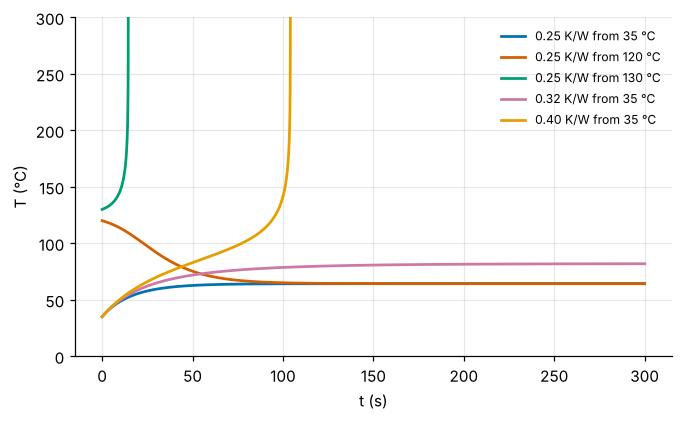

R_th = 0.40 K/W: crosses 150 °C at t = 101.2 s (ngspice: thermal_runaway.cir)


In [5]:
Ta, Pd, PL0, T0, Tc, Cth = 35.0, 80.0, 10.0, 25.0, 30.0, 50.0
def rhs(R):
    return lambda t, T: [(Pd + PL0 * math.exp((T[0] - T0) / Tc) - (T[0] - Ta) / R) / Cth]
hot = lambda t, T: T[0] - 300
hot.terminal = True
fig, ax = plt.subplots(figsize=(7, 4))
for R, T_start in [(0.25, 35), (0.25, 120), (0.25, 130), (0.32, 35), (0.40, 35)]:
    sol = solve_ivp(rhs(R), (0, 300), [T_start], events=hot, max_step=0.5, rtol=1e-9, atol=1e-9)
    end = f"runaway past 300 °C at t = {sol.t_events[0][0]:.1f} s" if sol.t_events[0].size else f"T(300 s) = {sol.y[0, -1]:.2f} °C"
    print(f"R_th = {R:.2f} K/W, start {T_start:3d} °C: {end}")
    ax.plot(sol.t, sol.y[0], label=f"{R:.2f} K/W from {T_start} °C")
ax.set_ylim(0, 300); ax.set_xlabel("t (s)"); ax.set_ylabel("T (°C)"); ax.legend(fontsize=8); plt.show()

cross = lambda t, T: T[0] - 150
cross.terminal = True
sol = solve_ivp(rhs(0.40), (0, 300), [35], events=cross, max_step=0.5, rtol=1e-10, atol=1e-10)
print(f"R_th = 0.40 K/W: crosses 150 °C at t = {sol.t_events[0][0]:.1f} s (ngspice: thermal_runaway.cir)")

Below the unstable equilibrium (124.9 °C), the chip returns to 64.25 °C; above it, the temperature runs away. At 0.32 K/W, just inside the critical 0.329 K/W, it still settles, but slowly and hot, because the loop gain is close to 1. At 0.40 K/W there is no equilibrium at all.

## Part 5 — ngspice

From the repository root, run `python tools/run_spice.py 02-02`. It runs three netlists:

- `rc_inputs.cir`: the ramp-tracking error at 1 ms (Example 02-02.3), the switched-on cosine's steady amplitude (Example 02-02.4) and the RL circuit of Problem 02-02.9;
- `thermal_rc.cir`: the thermal model of Example 02-02.5 as an RC network, settling at 64.25 °C;
- `thermal_runaway.cir`: the same model with $R_{th} = 0.40$ K/W, crossing 150 °C at about 101 s.

## Your turn

1. In Part 2, find the step at which the trapezoidal rule's factor $(1 - h/2)/(1 + h/2)$ becomes negative. What does the numerical solution look like for steps larger than that?
2. In Part 4, find numerically the starting temperature that separates recovery from runaway at $R_{th} = 0.25$ K/W, and compare it with the unstable equilibrium of the example.